# Engineered features in PCA and UMAP space

[Notebook 02](02_features.ipynb) asked whether the engineered features help a gradient-boosted probe that already has the raw data. This
notebook asks the same question of the **geometry** of the data: with each feature set, do the task families and the
controller classes (ID-safe, OOD-safe, OOD-dangerous) come apart in a linear projection (PCA) and in a
neighbourhood-preserving one (UMAP), in 2-D and 3-D?

The ablation repeats notebook 02's nine feature sets and adds a drop-one-family set for each family:

| set | columns |
|---|---|
| raw summaries (1 s) | last value, mean, SD, min, max of the 16 inputs over the 1 s window (80) |
| engineered only | the 29 engineered features (14 per leg + step regularity) |
| raw + engineered | both (109) |
| raw + *family* | raw summaries plus one family (jerk / high-frequency, polar phase, spectral, orientation) |
| raw + engineered − *family* | everything except one family |
| raw summaries (3 s), raw 3 s + spectral | the controls for the spectral features' longer history |

Every set is standardized column by column, then projected. Importance is measured three ways: PCA loadings (which
families carry the main axes of variation), participant-held-out k-nearest-neighbour accuracy in each space (can
held-out people's windows be labelled from their neighbours?), and silhouette (how cleanly the groups separate).
Interactive 3-D views are in section 4.

## Findings at a glance

- **Spectral features are the ones that matter in every space.** Adding stride regularity, step regularity and
  dominant frequency lifts participant-held-out k-NN accuracy for task family from 0.855 to 0.884 in the full feature
  space and from 0.807 to 0.839 in UMAP 3-D. Dropping them from the full set loses most of that (0.884 to 0.862 and
  0.846 to 0.817). Controller class follows the same pattern (0.808 to 0.842 full space). These gains are up to about
  a point smaller than when the features reported band-edge values (notebook 02, section 2.4).
- **The other families barely move the geometry.** Polar phase and thigh pitch add under one point. Jerk and
  high-frequency features add nothing and slightly blur UMAP (0.807 to 0.791), and dropping them from the full set
  helps a little.
- **Longer history is still the bigger lever, but here the spectral features add to it.** Raw summaries over 3 s
  reach 0.885 (full space and UMAP 3-D). Adding the spectral features to those reaches 0.908 and 0.912, a gain of 2 to
  3 points, where the boosted trees in notebook 02 found under 1.
- **PCA ranks the features differently, and the reason is variance.** The leading axes are movement vigour (PC1, 34% of
  variance: raw acceleration and gyro spread, jerk), hip posture (PC2: encoder, accelerometer, thigh pitch) and off-axis
  rotation (PC3). The spectral and polar features own only PC5 (4% of variance), a rhythm axis. Participant explains 2%
  or less of every axis. PC1, PC2 and PC5 are largely task (38–67%), while PC3 varies within tasks, for example with
  which way a person turns. So 2-D and 3-D PCA views show little difference between sets
  (k-NN 0.60–0.73), while neighbourhood-based views (full space, UMAP) show the spectral effect clearly.
- **Controller classes are not clusters in any space.** Their silhouettes are negative everywhere, while task families
  separate modestly (up to 0.21). ID-safe, OOD-safe and OOD-dangerous are defined by what the controller can handle,
  not by movement similarity, so they have to be learned from labels or mapped from task; they won't appear on their
  own in an unsupervised map.

In [1]:
import hashlib
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.metrics import balanced_accuracy_score, silhouette_score
from sklearn.model_selection import GroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', message = '.*n_jobs value.*')     # umap: a fixed seed means one thread, by design
warnings.filterwarnings('ignore', message = 'IProgress not found')   # umap's tqdm import
import umap

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature'):              # dataset-agnostic helpers, then the Nature data access
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import signals as sg
import features as ft

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 9})
pio.renderers.default = 'plotly_mimetype'          # rendered by JupyterLab and VS Code; keeps the saved notebook small
GROUPS = {'walking': ['normal_walk', 'incline_walk', 'walk_backward', 'weighted_walk', 'dynamic_walk', 'obstacle_walk'],
          'stairs / curbs / step-ups': ['stairs', 'curb_up', 'curb_down', 'step_ups'],
          'squat / lift / sit / lunge': ['squats', 'lift_weight', 'sit_to_stand', 'lunges'],
          'jump / run / cut / shuffle': ['jump', 'tire_run', 'cutting', 'side_shuffle'],
          'standing / unstructured': ['poses', 'tug_of_war', 'push', 'twister', 'meander', 'start_stop', 'turn_and_step', 'ball_toss']}
GROUP_C = dict(zip(GROUPS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#4a3aa7']))
CLASS = {**{t: 'ID-safe' for t in ['normal_walk', 'incline_walk', 'stairs', 'weighted_walk']},
         **{t: 'OOD-dangerous' for t in ['ball_toss', 'step_ups', 'tug_of_war', 'sit_to_stand']}}
CLASS_C = {'ID-safe': '#287da8', 'OOD-safe': '#dd791a', 'OOD-dangerous': '#a32d2d'}
FAMILIES = {'jerk / high-frequency': ['jerk_rms', 'jerk_peak', 'accel_hf_ratio', 'angular_accel_rms', 'gyro_hf_ratio'],
            'polar phase space': ['phase_sin', 'phase_cos', 'phase_rate_hz', 'phase_monotonicity', 'ring_cv'],
            'spectral': ['dominant_hz', 'spectral_entropy', 'stride_regularity'],
            'orientation': ['thigh_pitch']}
SHORT = {'jerk / high-frequency': 'jerk / HF', 'polar phase space': 'polar phase', 'spectral': 'spectral', 'orientation': 'orientation'}

## 1. The windows and the feature sets

The same in-task windows notebook 02 used, from its feature cache, sampled evenly across the five task families
(3,000 each, so no family dominates a neighbourhood or a principal axis). The 3 s raw summaries are computed for the
sampled windows only.

In [2]:
inv = nt.build_cache()
nt.build_feature_cache(stride = 10)
f = pd.read_parquet(nt.CACHE / 'features')
meta = inv.set_index('rec')
f['task'] = meta['task'].to_numpy()[f['rec'].to_numpy()]
f['subject'] = meta['subject'].to_numpy()[f['rec'].to_numpy()]
f['group'] = f['task'].map({t: g for g, ts in GROUPS.items() for t in ts})
f['controller_class'] = f['task'].map(CLASS).fillna('OOD-safe')
cols_of = lambda fam: [f'{c}_{s}' for c in FAMILIES[fam] for s in nt.SIDES] + (['step_regularity'] if fam == 'spectral' else [])
ENG = [c for fam in FAMILIES for c in cols_of(fam)]
RAW = [c for c in f if c.startswith('raw_')]
on = f[f['flag_l'] > 0].dropna(subset = ENG + RAW)
PER_FAMILY = 3000
d = on.groupby('group').sample(n = PER_FAMILY, random_state = 0).reset_index(drop = True)
parts = []
for r, g in d.groupby('rec'):
    sam = pd.read_parquet(nt.CACHE / 'samples' / f'{r:05d}.parquet')
    parts.append(nt.get_raw_summaries(sam, g['end'].to_numpy(), ft.WINDOW['spectral']).set_index(g.index))
RAW3 = [c.replace('raw_', 'raw3s_') for c in RAW]
d = d.join(pd.concat(parts).set_axis(RAW3, axis = 1)).dropna(subset = RAW3).reset_index(drop = True)
SETS = {'raw summaries (1 s)': RAW, 'engineered only': ENG, 'raw + engineered': RAW + ENG,
        **{f'raw + {SHORT[fam]}': RAW + cols_of(fam) for fam in FAMILIES},
        **{f'raw + engineered − {SHORT[fam]}': RAW + [c for c in ENG if c not in cols_of(fam)] for fam in FAMILIES},
        'raw summaries (3 s)': RAW3, 'raw 3 s + spectral': RAW3 + cols_of('spectral')}
print(f"{len(d):,} windows from {d.subject.nunique()} people; {len(SETS)} feature sets")
display(pd.crosstab(d['group'], d['controller_class']))
display(pd.Series({k: len(v) for k, v in SETS.items()}, name = 'columns').to_frame().T)

15,000 windows from 22 people; 13 feature sets


controller_class,ID-safe,OOD-dangerous,OOD-safe
group,,,
jump / run / cut / shuffle,0,0,3000
squat / lift / sit / lunge,0,1043,1957
stairs / curbs / step-ups,284,630,2086
standing / unstructured,0,468,2532
walking,1587,0,1413


,raw summaries (1 s),engineered only,raw + engineered,raw + jerk / HF,raw + polar phase,raw + spectral,raw + orientation,raw + engineered − jerk / HF,raw + engineered − polar phase,raw + engineered − spectral,raw + engineered − orientation,raw summaries (3 s),raw 3 s + spectral
columns,80,29,109,90,90,87,82,99,99,102,107,80,87


## 2. Projections

PCA and UMAP (30 neighbours, minimum distance 0.1, seed 0) in 2-D and 3-D for every set, on the standardized columns.
UMAP is the slow part (about half a minute per embedding); results are cached under `data/cache/nature/embeddings/`,
so later runs reuse them. Both projections are fitted on all sampled windows without labels; section 5's
participant-held-out scores therefore test how well a held-out person's windows sit among *other* people's windows
of the same kind, in a map that was drawn without knowing the kinds.

In [3]:
EMB = nt.CACHE / 'embeddings'
X_STD = {name: StandardScaler().fit_transform(d[cols].to_numpy(dtype = float)) for name, cols in SETS.items()}


def get_embedding(name, method, dims):
    """Cached 2-D or 3-D PCA or UMAP coordinates of one standardized feature set, keyed by its values."""
    key = hashlib.sha256(X_STD[name].tobytes() + f'|{method}|{dims}'.encode()).hexdigest()[:16]   # the data itself: new features, new key
    path = EMB / f'{key}.npy'
    if path.exists():
        points = np.load(path)
    else:
        model = PCA(n_components = dims, random_state = 0) if method == 'pca' else \
            umap.UMAP(n_components = dims, n_neighbors = 30, min_dist = 0.1, random_state = 0)
        points = model.fit_transform(X_STD[name]).astype(np.float32)
        EMB.mkdir(parents = True, exist_ok = True)
        np.save(path, points)
    return points


t0 = time.time()
emb = {(name, method, dims): get_embedding(name, method, dims) for name in SETS for method in ('pca', 'umap') for dims in (2, 3)}
print(f'{len(emb)} embeddings ready in {time.time() - t0:.0f} s')

52 embeddings ready in 0 s


### 2.1 What the principal axes are made of
For the full set (raw + engineered), the share of each of the first five principal components' squared loadings that
falls on each column family, the columns that load most, and how much of each component's variance is explained by
which participant it is versus which task it is. A family that owns a leading component shapes the geometry everything
else in this notebook looks at.

In [4]:
def get_column_family(c):
    family = 'spectral' if c == 'step_regularity' else next((SHORT[k] for k in FAMILIES if any(c.startswith(x + '_') for x in FAMILIES[k])), None)
    if family is None:
        family = 'raw: encoder' if 'hip_angle' in c else ('raw: accelerometer' if 'accel' in c else 'raw: gyro')
    return family


cols = SETS['raw + engineered']
pca = PCA(n_components = 5, random_state = 0).fit(X_STD['raw + engineered'])
load = pd.DataFrame(pca.components_.T ** 2, index = cols, columns = [f'PC{i + 1}' for i in range(5)])
share = load.groupby([get_column_family(c) for c in cols]).sum()
share.loc['explained variance'] = pca.explained_variance_ratio_
share.loc['engineered columns, share of all'] = len(ENG) / len(cols)
scores_pc = pd.DataFrame(pca.transform(X_STD['raw + engineered']), columns = share.columns)
for label, key in (('variance explained by participant', 'subject'), ('variance explained by task', 'task')):
    share.loc[label] = [scores_pc[c].groupby(d[key].to_numpy()).transform('mean').var() / scores_pc[c].var() for c in scores_pc]
display(share.round(3))
top = pd.DataFrame({pc: [f"{c.removeprefix('raw_')} ({load.loc[c, pc]:.2f})" for c in load[pc].sort_values(ascending = False).index[:5]]
                    for pc in load}, index = [f'top {i + 1}' for i in range(5)])
display(top)
kept = pd.DataFrame({name: [PCA(n_components = 3, random_state = 0).fit(X).explained_variance_ratio_[:k].sum() for k in (2, 3)]
                     for name, X in X_STD.items()}, index = ['variance in 2 PCs', 'variance in 3 PCs']).T
display(kept.round(3))

,PC1,PC2,PC3,PC4,PC5
jerk / HF,0.140,0.005,0.001,0.032,0.092
orientation,0.000,0.070,0.000,0.017,0.003
polar phase,0.047,0.021,0.003,0.118,0.183
raw: accelerometer,0.332,0.338,0.011,0.119,0.141
raw: encoder,0.121,0.508,0.008,0.442,0.203
raw: gyro,0.292,0.012,0.976,0.215,0.214
spectral,0.068,0.046,0.001,0.058,0.164
explained variance,0.340,0.097,0.053,0.048,0.042
"engineered columns, share of all",0.266,0.266,0.266,0.266,0.266
variance explained by participant,0.015,0.021,0.002,0.010,0.016


,PC1,PC2,PC3,PC4,PC5
top 1,angular_accel_rms_r (0.02),hip_angle_l_min (0.07),thigh_imu_r_gyro_y_mean (0.14),hip_angle_l_velocity_mean (0.06),step_regularity (0.05)
top 2,angular_accel_rms_l (0.02),hip_angle_l_mean (0.07),thigh_imu_l_gyro_y_mean (0.14),hip_angle_r_velocity_mean (0.06),stride_regularity_l (0.05)
top 3,jerk_rms_l (0.02),hip_angle_r_min (0.07),thigh_imu_r_gyro_x_mean (0.09),hip_angle_l_sd (0.05),stride_regularity_r (0.05)
top 4,jerk_rms_r (0.02),hip_angle_r_mean (0.07),thigh_imu_l_gyro_x_mean (0.09),hip_angle_r_sd (0.05),phase_monotonicity_l (0.03)
top 5,thigh_imu_r_accel_y_sd (0.02),hip_angle_r_last (0.05),thigh_imu_l_gyro_y_last (0.08),thigh_imu_r_gyro_z_mean (0.05),phase_monotonicity_r (0.03)


,variance in 2 PCs,variance in 3 PCs
raw summaries (1 s),0.463,0.535
engineered only,0.464,0.535
raw + engineered,0.436,0.490
raw + jerk / HF,0.470,0.534
raw + polar phase,0.431,0.496
raw + spectral,0.457,0.524
raw + orientation,0.460,0.531
raw + engineered − jerk / HF,0.428,0.487
raw + engineered − polar phase,0.461,0.520
raw + engineered − spectral,0.439,0.496


## 3. The 2-D maps

One panel per feature set, coloured by task family. UMAP first, then PCA.

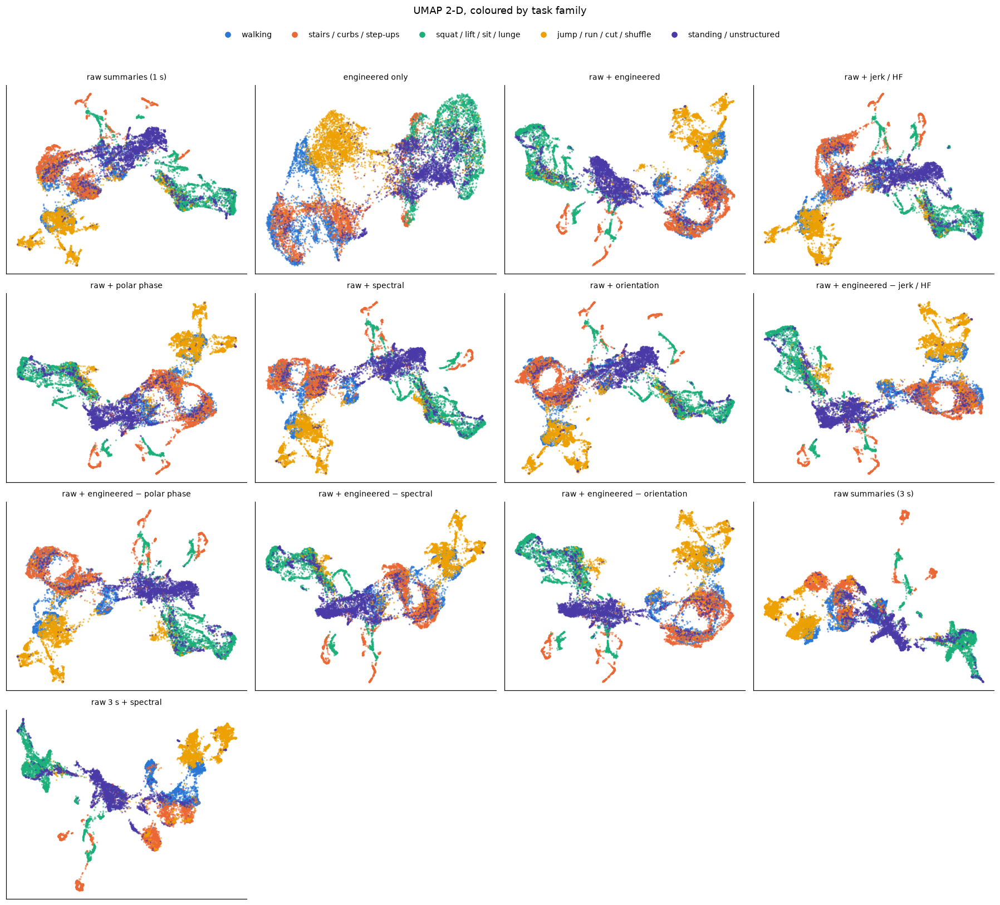

In [5]:
def plot_grid(method, color_by, palette, title):
    names = list(SETS)
    ncol = 4
    nrow = int(np.ceil(len(names) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize = (4.1 * ncol, 3.7 * nrow))
    labels = d[color_by].to_numpy()
    for ax, name in zip(axes.flat, names):
        pts = emb[(name, method, 2)]
        for lab, color in palette.items():
            m = labels == lab
            ax.scatter(pts[m, 0], pts[m, 1], s = 1.5, alpha = .45, color = color, label = lab, rasterized = True)
        ax.set_title(name, fontsize = 9); ax.set_xticks([]); ax.set_yticks([])
    for ax in list(axes.flat)[len(names):]:
        ax.axis('off')
    handles = [plt.Line2D([], [], marker = 'o', ls = '', color = c, label = l, markersize = 6) for l, c in palette.items()]
    fig.suptitle(title, y = .995, fontsize = 12)
    fig.legend(handles = handles, loc = 'upper center', bbox_to_anchor = (.5, .975), ncol = len(palette), fontsize = 9, frameon = False)
    plt.tight_layout(rect = (0, 0, 1, .95)); plt.show()


plot_grid('umap', 'group', GROUP_C, 'UMAP 2-D, coloured by task family')

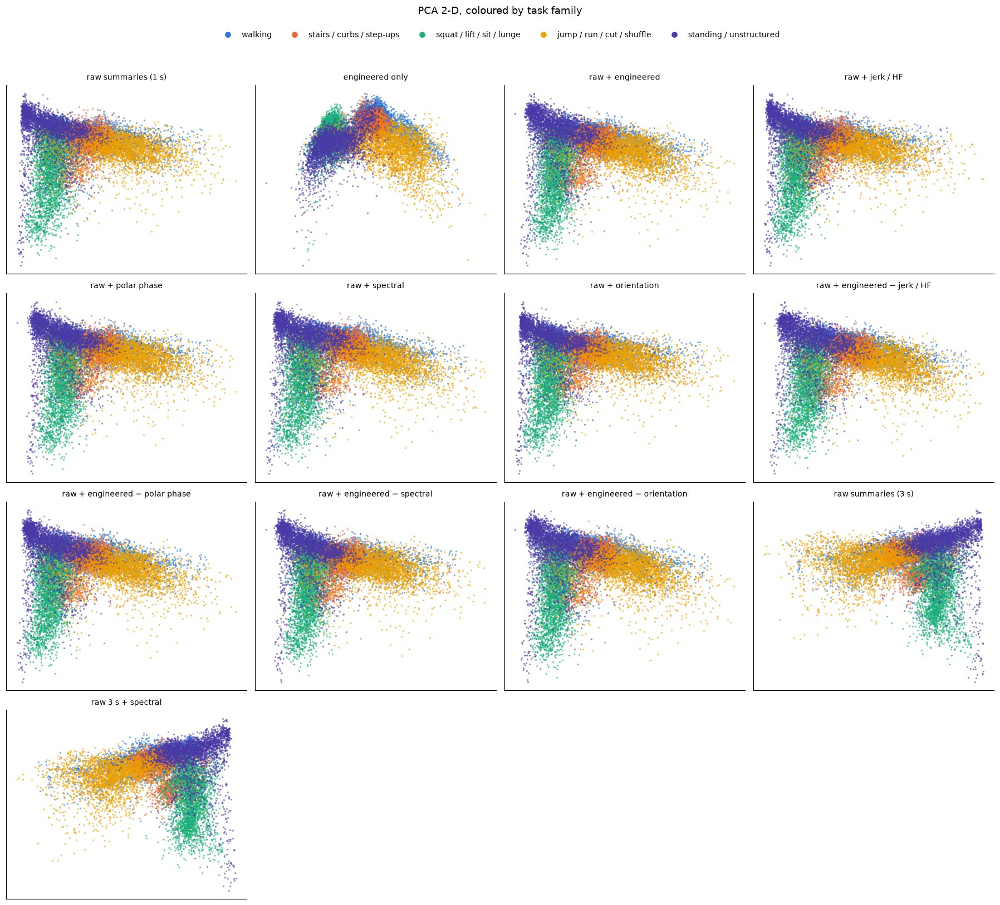

In [6]:
plot_grid('pca', 'group', GROUP_C, 'PCA 2-D, coloured by task family')

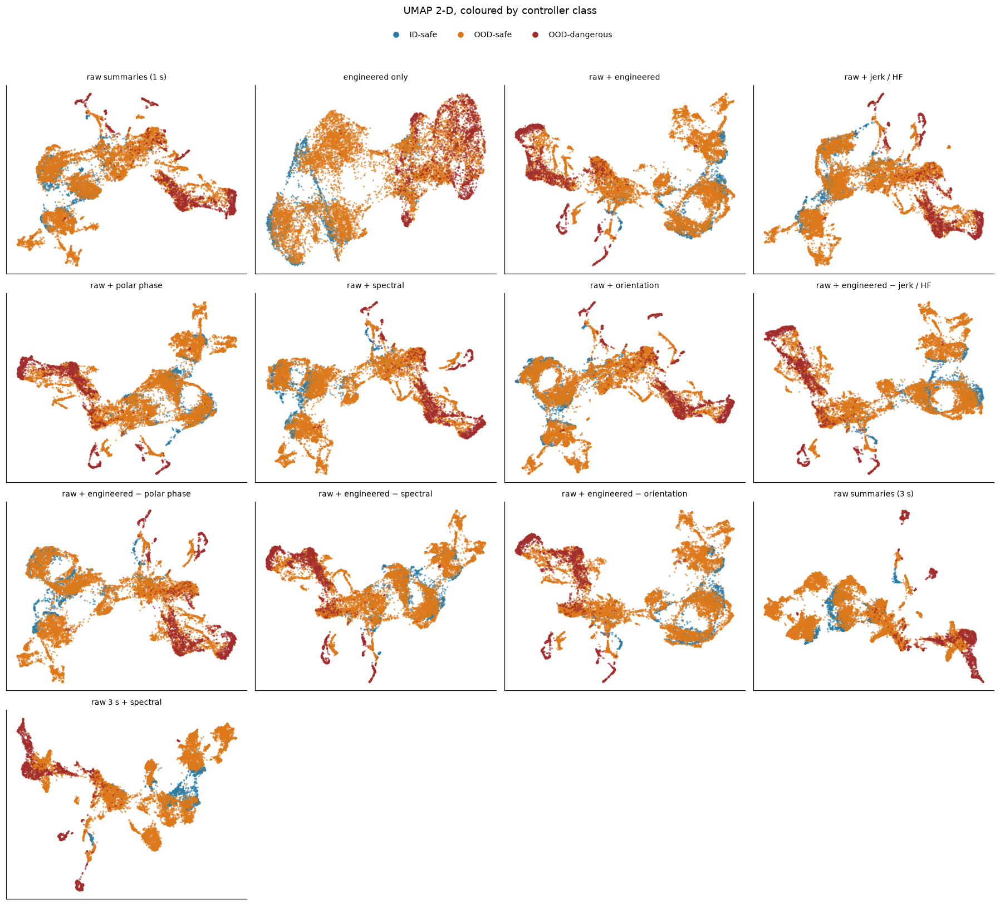

In [7]:
plot_grid('umap', 'controller_class', CLASS_C, 'UMAP 2-D, coloured by controller class')

## 4. Interactive 3-D maps

Two figures, one coloured by task family and one by controller class. The dropdown switches between feature sets and
between UMAP and PCA; drag to rotate, scroll to zoom, click a legend entry to hide a group, double-click to isolate it.
Each view shows the same 3,000 windows (600 per family) so views can be compared point for point; hover shows the task
and participant. Only two 3-D scenes are used, because browsers cap live WebGL contexts per page and extra scenes
render blank.

In [8]:
rng = np.random.default_rng(0)
SHOW = np.sort(np.concatenate([rng.choice(np.flatnonzero(d['group'].to_numpy() == g), 600, replace = False) for g in GROUPS]))
HOVER = (d['task'] + ' · ' + d['subject']).to_numpy()[SHOW]


def build_3d(color_by, palette, title):
    """One 3-D scene; a dropdown makes one (feature set, projection) view visible at a time."""
    fig, views = go.Figure(), []
    labels = d[color_by].to_numpy()[SHOW]
    for name in SETS:
        for method in ('umap', 'pca'):
            pts = np.round(emb[(name, method, 3)][SHOW], 3)
            first = len(fig.data)
            for lab, color in palette.items():
                m = labels == lab
                fig.add_trace(go.Scatter3d(x = pts[m, 0], y = pts[m, 1], z = pts[m, 2], mode = 'markers', name = lab,
                                           legendgroup = lab, visible = not views, text = HOVER[m],
                                           hovertemplate = '%{text}<extra>' + lab + '</extra>',
                                           marker = dict(size = 2.2, color = color, opacity = .65)))
            views.append((f'{method.upper()} · {name}', range(first, len(fig.data))))
    buttons = []
    for label, idx in views:
        visible = np.zeros(len(fig.data), dtype = bool)
        visible[list(idx)] = True
        buttons.append(dict(label = label, method = 'update', args = [{'visible': visible.tolist()}, {'title.text': f'{title}: {label}'}]))
    fig.update_layout(title = dict(text = f'{title}: {views[0][0]}', x = .02), height = 680, template = 'plotly_white',
                      margin = dict(l = 0, r = 0, t = 90, b = 0), legend = dict(itemsizing = 'constant'),
                      scene = dict(xaxis_title = '1', yaxis_title = '2', zaxis_title = '3'),
                      updatemenus = [dict(buttons = buttons, direction = 'down', x = .02, y = 1.08, xanchor = 'left', yanchor = 'top')])
    return fig


build_3d('group', GROUP_C, 'Task family').show(config = {'scrollZoom': True, 'displaylogo': False})

In [9]:
build_3d('controller_class', CLASS_C, 'Controller class').show(config = {'scrollZoom': True, 'displaylogo': False})

## 5. Importance in each space

For every feature set and every space (the full standardized space, PCA 2-D and 3-D, UMAP 2-D and 3-D):

- **k-NN balanced accuracy**, participant-held-out: five folds grouped by person; each held-out window takes the
  majority label of its 15 nearest windows from *other* people. High means the space puts the same kind of movement
  together across people.
- **Silhouette** (task family and controller class), on 5,000 windows: positive means groups are tighter than they are
  far apart; near 0 means they overlap.

Notebook 02's boosted-tree probe is shown beside them for the sets it ran.

In [10]:
folds = list(GroupKFold(5).split(d, groups = d['subject']))
SPACES = {'full space': lambda n: X_STD[n], 'PCA 2-D': lambda n: emb[(n, 'pca', 2)], 'PCA 3-D': lambda n: emb[(n, 'pca', 3)],
          'UMAP 2-D': lambda n: emb[(n, 'umap', 2)], 'UMAP 3-D': lambda n: emb[(n, 'umap', 3)]}
sil_idx = np.random.default_rng(1).choice(len(d), 5000, replace = False)


def get_knn_accuracy(points, target):
    y = d[target].to_numpy()
    pred = np.empty(len(y), dtype = object)
    for tr, te in folds:
        pred[te] = KNeighborsClassifier(n_neighbors = 15).fit(points[tr], y[tr]).predict(points[te])
    return balanced_accuracy_score(y, pred)


t0 = time.time()
rows = []
for name in SETS:
    for space, get in SPACES.items():
        pts = get(name)
        rows.append(dict(set = name, space = space,
                         family = get_knn_accuracy(pts, 'group'), controller_class = get_knn_accuracy(pts, 'controller_class'),
                         silhouette_family = silhouette_score(pts[sil_idx], d['group'].to_numpy()[sil_idx]),
                         silhouette_class = silhouette_score(pts[sil_idx], d['controller_class'].to_numpy()[sil_idx])))
scores = pd.DataFrame(rows)
print(f'scored {len(scores)} (set, space) pairs in {time.time() - t0:.0f} s')
BOOSTED = pd.DataFrame({'family': {'raw summaries (1 s)': .906, 'engineered only': .871, 'raw + engineered': .939, 'raw + jerk / HF': .906,
                                   'raw + polar phase': .917, 'raw + spectral': .936, 'raw + orientation': .904,
                                   'raw summaries (3 s)': .945, 'raw 3 s + spectral': .950},
                        'controller_class': {'raw summaries (1 s)': .843, 'engineered only': .823, 'raw + engineered': .876, 'raw + jerk / HF': .841,
                                             'raw + polar phase': .852, 'raw + spectral': .875, 'raw + orientation': .845,
                                             'raw summaries (3 s)': .889, 'raw 3 s + spectral': .898}})
for target, label in (('family', 'task family'), ('controller_class', 'controller class')):
    table = scores.pivot(index = 'set', columns = 'space', values = target).loc[list(SETS), list(SPACES)]
    table['boosted trees (nb 02)'] = BOOSTED[target].reindex(table.index)
    print(f'k-NN balanced accuracy, {label} (participant-held-out)')
    display(table.round(3))
sil = scores.pivot(index = 'set', columns = 'space', values = ['silhouette_family', 'silhouette_class']).loc[list(SETS)]
sil = sil.loc[:, [(m, s) for m in ('silhouette_family', 'silhouette_class') for s in ('full space', 'PCA 3-D', 'UMAP 3-D')]]
print('silhouette'); display(sil.round(3))

scored 65 (set, space) pairs in 28 s
k-NN balanced accuracy, task family (participant-held-out)


space,full space,PCA 2-D,PCA 3-D,UMAP 2-D,UMAP 3-D,boosted trees (nb 02)
set,,,,,,
raw summaries (1 s),0.855,0.604,0.660,0.779,0.807,0.906
engineered only,0.837,0.595,0.692,0.768,0.798,0.871
raw + engineered,0.884,0.630,0.683,0.810,0.846,0.939
raw + jerk / HF,0.851,0.607,0.660,0.775,0.791,0.906
raw + polar phase,0.861,0.607,0.663,0.790,0.812,0.917
raw + spectral,0.884,0.633,0.687,0.815,0.839,0.936
raw + orientation,0.861,0.597,0.659,0.782,0.814,0.904
raw + engineered − jerk / HF,0.886,0.623,0.681,0.821,0.849,NaN
raw + engineered − polar phase,0.880,0.629,0.684,0.811,0.838,NaN


k-NN balanced accuracy, controller class (participant-held-out)


space,full space,PCA 2-D,PCA 3-D,UMAP 2-D,UMAP 3-D,boosted trees (nb 02)
set,,,,,,
raw summaries (1 s),0.808,0.524,0.577,0.690,0.726,0.843
engineered only,0.757,0.449,0.547,0.656,0.702,0.823
raw + engineered,0.841,0.541,0.593,0.722,0.770,0.876
raw + jerk / HF,0.804,0.530,0.577,0.696,0.710,0.841
raw + polar phase,0.815,0.506,0.564,0.708,0.739,0.852
raw + spectral,0.842,0.562,0.607,0.737,0.757,0.875
raw + orientation,0.811,0.520,0.573,0.703,0.747,0.845
raw + engineered − jerk / HF,0.843,0.539,0.595,0.734,0.775,NaN
raw + engineered − polar phase,0.840,0.549,0.604,0.728,0.764,NaN


silhouette


silhouette_family                  silhouette_class                 
space                                 full space PCA 3-D UMAP 3-D       full space PCA 3-D UMAP 3-D
set                                                                                                
raw summaries (1 s)                        0.012   0.030    0.114           -0.030  -0.064   -0.088
engineered only                            0.020   0.042    0.068           -0.042  -0.102   -0.138
raw + engineered                           0.018   0.043    0.121           -0.031  -0.071   -0.090
raw + jerk / HF                            0.011   0.031    0.115           -0.033  -0.065   -0.105
raw + polar phase                          0.012   0.032    0.114           -0.031  -0.071   -0.096
raw + spectral                             0.022   0.043    0.124           -0.031  -0.069   -0.103
raw + orientation                          0.013   0.031    0.111           -0.028  -0.060   -0.088
raw + engineered − jerk / HF               0.020   0.043    0.129           -0.029  -0.071   -0.083
raw + engineered − polar phase             0.020   0.043    0.106           -0.030  -0.065   -0.106
raw + engineered − spectral                0.012   0.033    0.104           -0.031  -0.066   -0.096
raw + engineered − orientation             0.017   0.042    0.115           -0.033  -0.076   -0.094
raw summaries (3 s)                        0.034   0.072    0.144           -0.027  -0.045   -0.111
raw 3 s + spectral                         0.045   0.100    0.209           -0.023  -0.022   -0.067

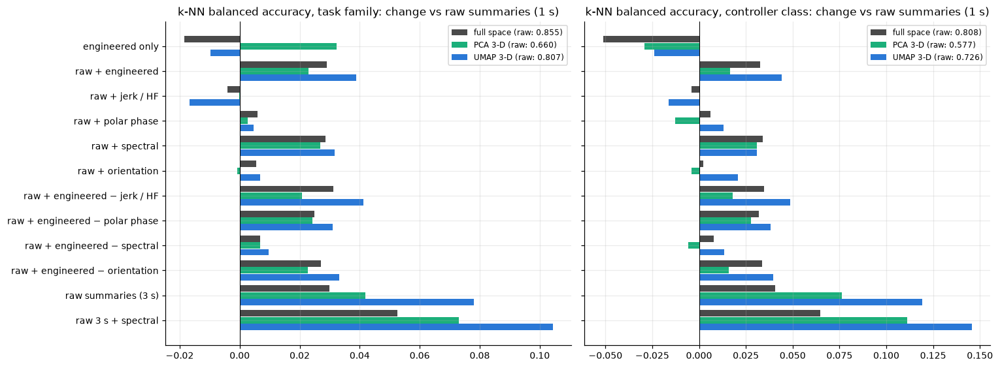

In [11]:
base = scores[scores.set == 'raw summaries (1 s)'].set_index('space')
fig, axes = plt.subplots(1, 2, figsize = (14, 5.2), sharey = True)
names = [n for n in SETS if n != 'raw summaries (1 s)']
space_c = {'full space': '#4a4a4a', 'PCA 3-D': '#1baf7a', 'UMAP 3-D': '#2a78d6'}
for ax, (target, label) in zip(axes, (('family', 'task family'), ('controller_class', 'controller class'))):
    y = np.arange(len(names))
    for k, (space, color) in enumerate(space_c.items()):
        vals = [scores[(scores.set == n) & (scores.space == space)][target].item() - base.loc[space, target] for n in names]
        ax.barh(y + (k - 1) * .27, vals, height = .26, color = color, label = f'{space} (raw: {base.loc[space, target]:.3f})')
    ax.axvline(0, color = 'k', lw = .7); ax.set_yticks(y, names); ax.set_title(f'k-NN balanced accuracy, {label}: change vs raw summaries (1 s)')
    ax.legend(fontsize = 8, loc = 'upper right')
axes[0].invert_yaxis(); plt.tight_layout(); plt.show()

## 6. What this says about the features

| family | importance in PCA / UMAP space | agrees with the boosted trees (notebook 02)? |
|---|---|---|
| spectral | **high.** Adding it gives +2.9 (full) and +3.2 (UMAP 3-D) k-NN points for task family, dropping it costs about the same, and it shares the rhythm axis (PC5) with polar phase | yes, and it adds more beyond the 3 s context here (+2 to +3 against under 1) |
| polar phase space | **low.** +0.6 / +0.5 points; shares PC4–PC5 | yes. Its value is as a controller phase signal, not for separation |
| orientation (fused thigh pitch) | **low.** +0.6 / +0.7 points; part of the posture axis PC2 | yes |
| jerk and high-frequency | **none, slightly negative.** It adds to the vigour axis (PC1) that raw spread already spans, and blurs UMAP | yes |

**Implications**

- **For any density-based detector** (LOF on a latent, as in the awareness pipeline), give the model at least 3 s of
  context or the spectral summaries. That is where neighbourhoods get cleaner across people, the property LOF relies on.
- **Leave jerk and the high-frequency ratios out of embedding and novelty inputs.** They add variance without
  separation. Keep them only for a fault detector.
- **Map controller classes from task family, or learn them with labels.** No unsupervised geometry recovers them.
- **Use UMAP or the full feature space, not 2-D or 3-D PCA, to judge features.** PCA's leading axes are chosen by
  variance, and the features that matter here carry little of it.

**Limits**

- UMAP and PCA are fitted on all sampled windows, including the held-out participants' (labels are never used). The
  k-NN scores therefore measure cross-person consistency in a shared map, not a deployable classifier.
- The sample is 15,000 windows, balanced across families. Differences under about 0.01 are within noise.
- Columns are standardized and weighted equally, so the 80 raw columns dominate distances over the 29 engineered ones.
  A feature has to be strongly informative to show up at all.